# PRIM — Where Does Each Policy Fail? (Degraded Distances)

For each policy, compare against stovepipe. Find the parameter box where the policy
produces WORSE mortality than stovepipe (delta > 0).

Extended distance ranges: same_bn 10-40, inter_bn 15-70.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ema_workbench.analysis import prim

RESULTS_PATH = _root / "data_cluster" / "loose_ranges" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

stove = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
amb   = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)
fac   = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)].sort_values("scenario").reset_index(drop=True)
both  = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 1)].sort_values("scenario").reset_index(drop=True)

assert (stove["scenario"].values == amb["scenario"].values).all()
assert (stove["scenario"].values == fac["scenario"].values).all()
assert (stove["scenario"].values == both["scenario"].values).all()
print(f"Matched scenarios: {len(stove)}")

C:\Users\User\Documents\thesis\medevac_model\.venv\Lib\site-packages\ema_workbench\em_framework\__init__.py:101: UserWarning: ipyparallel not installed - IpyparalleEvaluator not available
  warnings.warn("ipyparallel not installed - IpyparalleEvaluator not available")


Loaded 98304 runs
Matched scenarios: 24576


## Summary — How often does each policy fail vs stovepipe?

In [2]:
comparisons = [
    ("Amb only",  amb),
    ("Fac only",  fac),
    ("Both",      both),
]

for label, policy_df in comparisons:
    delta = policy_df["death_rate_T1_BCAS"].values - stove["death_rate_T1_BCAS"].values
    n_worse = (delta > 0.01).sum()
    n_better = (delta < -0.01).sum()
    n_neutral = len(delta) - n_worse - n_better
    print(f"{label:12s}  worse: {n_worse:5d} ({n_worse/len(delta):5.1%})  better: {n_better:5d} ({n_better/len(delta):5.1%})  neutral: {n_neutral:5d} ({n_neutral/len(delta):5.1%})  median delta: {np.median(delta):.4f}")

Amb only      worse:  1554 ( 6.3%)  better: 18696 (76.1%)  neutral:  4326 (17.6%)  median delta: -0.2500
Fac only      worse:   594 ( 2.4%)  better:   671 ( 2.7%)  neutral: 23311 (94.9%)  median delta: 0.0000
Both          worse:  1203 ( 4.9%)  better: 19566 (79.6%)  neutral:  3807 (15.5%)  median delta: -0.3000


## PRIM — Where does ambulance pooling NOT help? (delta >= -0.01)

Amb pooling does NOT help: 5880 / 24576 (23.9%)

Peeling trajectory (43 steps):
    coverage  density  mass  res_dim
0      1.000    0.239 1.000        0
1      0.979    0.248 0.946        1
2      0.960    0.257 0.893        1
3      0.939    0.268 0.839        1
4      0.917    0.279 0.786        1
5      0.896    0.293 0.732        1
6      0.870    0.307 0.678        1
7      0.854    0.318 0.643        1
8      0.836    0.329 0.607        1
9      0.819    0.343 0.571        1
10     0.799    0.357 0.536        1
11     0.777    0.372 0.500        1
12     0.753    0.388 0.464        1
13     0.734    0.410 0.428        1
14     0.706    0.430 0.393        1
15     0.674    0.451 0.357        1
16     0.638    0.475 0.322        1
17     0.616    0.486 0.303        1
18     0.594    0.497 0.286        1
19     0.570    0.510 0.267        2
20     0.547    0.525 0.249        2
21     0.523    0.537 0.233        2
22     0.495    0.550 0.215        2
23     0.472    0.561 0.201     

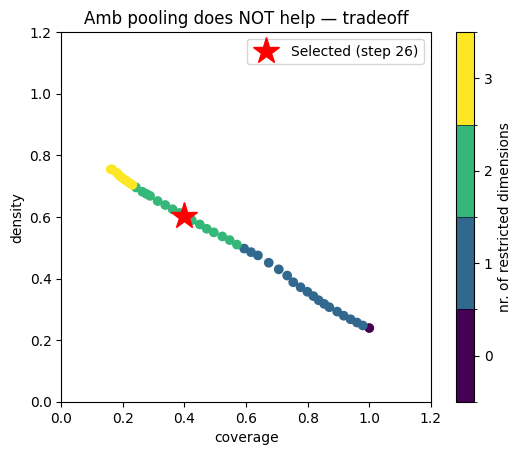


Selected step 26:
coverage       0.398299
density        0.603608
id            26.000000
k           2342.000000
mass           0.157878
mean           0.603608
n           3880.000000
res_dim        2.000000
Name: 26, dtype: float64

                    box 26                             
                       min   max      qp value qp value
ccp_r1_inter_bn_min   57.5  70.0  0.000000e+00      NaN
ccp_r1_same_bn_min    19.5  40.0  1.082098e-19      NaN


In [3]:
x = stove[UNCERTAINTIES].astype(float)

delta_amb = amb["death_rate_T1_BCAS"].values - stove["death_rate_T1_BCAS"].values
y_amb_no_help = delta_amb >= -0.01
print(f"Amb pooling does NOT help: {y_amb_no_help.sum()} / {len(y_amb_no_help)} ({y_amb_no_help.mean():.1%})")

if y_amb_no_help.sum() >= 10:
    p_amb = prim.Prim(x, y_amb_no_help, threshold=0.5)
    box_amb = p_amb.find_box()
    
    traj = box_amb.peeling_trajectory
    print(f"\nPeeling trajectory ({len(traj)} steps):")
    print(traj[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))
    
    good = traj[(traj["density"] > 0.60) & (traj["coverage"] > 0.3)]
    if len(good) > 0:
        best_idx = good.index[0]
    else:
        good = traj[traj["density"] > 0.40]
        best_idx = good.index[0] if len(good) > 0 else len(traj) - 1
    
    box_amb.select(best_idx)
    box_amb.show_tradeoff()
    sel = traj.iloc[best_idx]
    plt.plot(sel["coverage"], sel["density"], "r*", markersize=20, zorder=5, label=f"Selected (step {best_idx})")
    plt.legend()
    plt.title("Amb pooling does NOT help — tradeoff")
    plt.show()
    
    print(f"\nSelected step {best_idx}:")
    box_amb.inspect()
else:
    print("Too few cases for PRIM.")

## PRIM — Where does facility pooling NOT help? (delta >= -0.01)

Fac pooling does NOT help: 23905 / 24576 (97.3%)

Peeling trajectory (18 steps):
    coverage  density  mass  res_dim
0      1.000    0.973 1.000        0
1      0.953    0.980 0.946        1
2      0.905    0.985 0.893        1
3      0.853    0.989 0.839        1
4      0.801    0.992 0.786        1
5      0.748    0.994 0.732        1
6      0.694    0.995 0.678        1
7      0.658    0.996 0.643        1
8      0.625    0.996 0.611        2
9      0.594    0.996 0.580        2
10     0.565    0.997 0.551        2
11     0.471    0.997 0.460        3
12     0.377    0.998 0.367        3
13     0.358    0.998 0.349        3
14     0.340    0.999 0.331        3
15     0.323    0.999 0.314        3
16     0.243    0.999 0.236        3
17     0.247    0.999 0.240        3


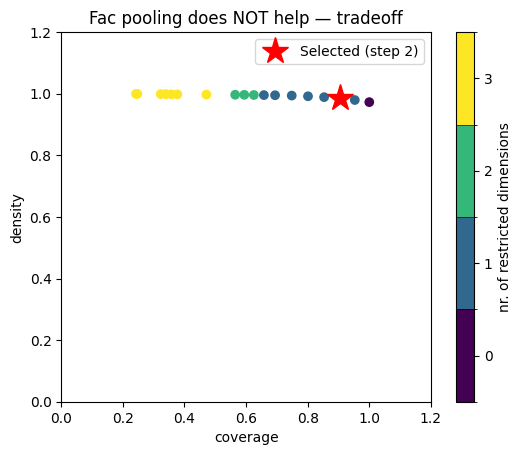


Selected step 2:
coverage        0.904622
density         0.985283
id              2.000000
k           21625.000000
mass            0.893066
mean            0.985283
n           21948.000000
res_dim         1.000000
Name: 2, dtype: float64

                    box 2                             
                      min   max      qp value qp value
ccp_r1_inter_bn_min  20.5  70.0  4.229276e-36      NaN


In [4]:
delta_fac = fac["death_rate_T1_BCAS"].values - stove["death_rate_T1_BCAS"].values
y_fac_no_help = delta_fac >= -0.01
print(f"Fac pooling does NOT help: {y_fac_no_help.sum()} / {len(y_fac_no_help)} ({y_fac_no_help.mean():.1%})")

if y_fac_no_help.sum() >= 10:
    p_fac = prim.Prim(x, y_fac_no_help, threshold=0.5)
    box_fac = p_fac.find_box()
    
    traj = box_fac.peeling_trajectory
    print(f"\nPeeling trajectory ({len(traj)} steps):")
    print(traj[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))
    
    good = traj[(traj["density"] > 0.98) & (traj["coverage"] > 0.3)]
    if len(good) > 0:
        best_idx = good.index[0]
    else:
        good = traj[traj["density"] > 0.95]
        best_idx = good.index[0] if len(good) > 0 else len(traj) - 1
    
    box_fac.select(best_idx)
    box_fac.show_tradeoff()
    sel = traj.iloc[best_idx]
    plt.plot(sel["coverage"], sel["density"], "r*", markersize=20, zorder=5, label=f"Selected (step {best_idx})")
    plt.legend()
    plt.title("Fac pooling does NOT help — tradeoff")
    plt.show()
    
    print(f"\nSelected step {best_idx}:")
    box_fac.inspect()
else:
    print("Too few cases for PRIM.")

## PRIM — Where does both pooling NOT help? (delta >= -0.01)

Both pooling does NOT help: 5010 / 24576 (20.4%)

Peeling trajectory (43 steps):
    coverage  density  mass  res_dim
0      1.000    0.204 1.000        0
1      0.979    0.211 0.946        1
2      0.960    0.219 0.893        1
3      0.940    0.228 0.839        1
4      0.917    0.238 0.786        1
5      0.893    0.249 0.732        1
6      0.864    0.260 0.678        1
7      0.847    0.268 0.643        1
8      0.828    0.278 0.607        1
9      0.811    0.289 0.571        1
10     0.792    0.301 0.536        1
11     0.772    0.315 0.500        1
12     0.748    0.329 0.464        1
13     0.729    0.347 0.428        1
14     0.702    0.364 0.393        1
15     0.673    0.384 0.357        1
16     0.640    0.406 0.322        1
17     0.622    0.418 0.303        1
18     0.601    0.429 0.286        1
19     0.578    0.440 0.268        1
20     0.556    0.453 0.250        1
21     0.533    0.468 0.232        1
22     0.512    0.480 0.217        2
23     0.490    0.493 0.203    

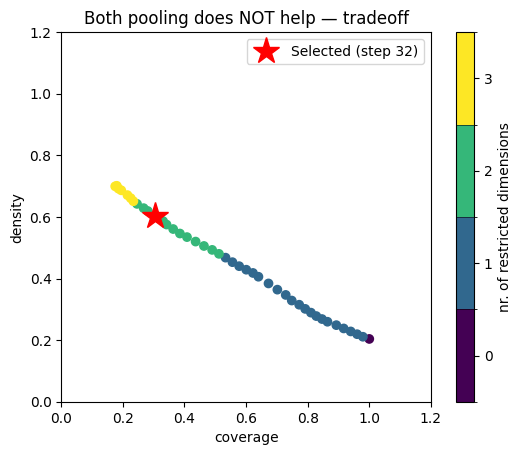


Selected step 32:
coverage       0.304990
density        0.602999
id            32.000000
k           1528.000000
mass           0.103109
mean           0.602999
n           2534.000000
res_dim        2.000000
Name: 32, dtype: float64

                    box 32                             
                       min   max      qp value qp value
ccp_r1_inter_bn_min   60.5  70.0  0.000000e+00      NaN
ccp_r1_same_bn_min    22.5  40.0  3.065041e-23      NaN


In [5]:
delta_both = both["death_rate_T1_BCAS"].values - stove["death_rate_T1_BCAS"].values
y_both_no_help = delta_both >= -0.01
print(f"Both pooling does NOT help: {y_both_no_help.sum()} / {len(y_both_no_help)} ({y_both_no_help.mean():.1%})")

if y_both_no_help.sum() >= 10:
    p_both = prim.Prim(x, y_both_no_help, threshold=0.5)
    box_both = p_both.find_box()
    
    traj = box_both.peeling_trajectory
    print(f"\nPeeling trajectory ({len(traj)} steps):")
    print(traj[["coverage", "density", "mass", "res_dim"]].to_string(float_format="%.3f"))
    
    good = traj[(traj["density"] > 0.60) & (traj["coverage"] > 0.3)]
    if len(good) > 0:
        best_idx = good.index[0]
    else:
        good = traj[traj["density"] > 0.40]
        best_idx = good.index[0] if len(good) > 0 else len(traj) - 1
    
    box_both.select(best_idx)
    box_both.show_tradeoff()
    sel = traj.iloc[best_idx]
    plt.plot(sel["coverage"], sel["density"], "r*", markersize=20, zorder=5, label=f"Selected (step {best_idx})")
    plt.legend()
    plt.title("Both pooling does NOT help — tradeoff")
    plt.show()
    
    print(f"\nSelected step {best_idx}:")
    box_both.inspect()
else:
    print("Too few cases for PRIM.")

## Delta Distributions — All 3 Comparisons

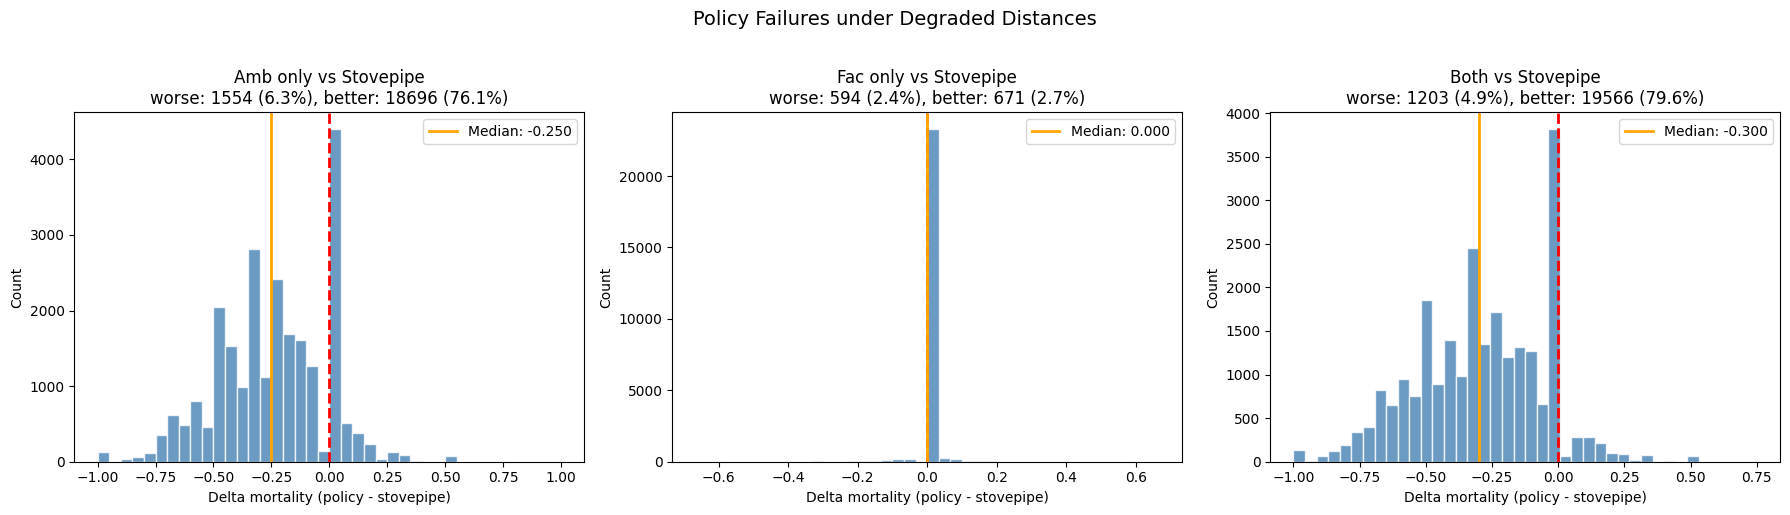

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (label, policy_df) in zip(axes, comparisons):
    delta = policy_df["death_rate_T1_BCAS"].values - stove["death_rate_T1_BCAS"].values
    ax.hist(delta, bins=40, color="steelblue", alpha=0.8, edgecolor="white")
    ax.axvline(0, color="red", linewidth=2, linestyle="--")
    ax.axvline(np.median(delta), color="orange", linewidth=2, label=f"Median: {np.median(delta):.3f}")
    n_worse = (delta > 0.01).sum()
    n_better = (delta < -0.01).sum()
    ax.set_title(f"{label} vs Stovepipe\nworse: {n_worse} ({n_worse/len(delta):.1%}), better: {n_better} ({n_better/len(delta):.1%})")
    ax.set_xlabel("Delta mortality (policy - stovepipe)")
    ax.set_ylabel("Count")
    ax.legend()

fig.suptitle("Policy Failures under Degraded Distances", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()